In [4]:
%matplotlib inline
import time
import sys
sys.path.append("..")
import numpy as np
import matplotlib.pyplot as plt
from joblib import Memory
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from skimage import color
from utils import ml_utilities
from utils import ml_visualization
import cv2

# --- Contrast stretching on the brightness (2-98% percentile) ---
def _u8(img):
    if img.dtype == np.uint8: return img
    img = np.asarray(img, dtype=np.float32)
    if img.max() <= 1.0: img = img * 255.0
    return np.clip(img, 0, 255).astype(np.uint8)

def contrast_stretch(img, lo=2, hi=98):
    img = _u8(img)
    def stretch(ch):
        a, b = np.percentile(ch, (lo, hi))
        if b <= a: return ch
        return np.clip((ch.astype(np.float32) - a) * 255.0 / (b - a), 0, 255).astype(np.uint8)
    if img.ndim == 2:
        return stretch(img)
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    lab[..., 0] = stretch(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

def gaussian_blur(img, ksize=(9,9), sigma=1):
    return cv2.GaussianBlur(img, ksize, sigma)

def apply_sobel(imgs, ksize=5):
    """
    Applica il filtro Sobel (gradiente orizzontale + verticale) a una lista di immagini.
    Restituisce un array numpy di immagini grayscale uint8, shape (N, H, W).
    """
    result = []
    for im in imgs:
        # Sobel lavora su un singolo canale: converto se l'immagine è a colori
        if im.ndim == 3:
            im = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)  # usa BGR2GRAY se le immagini sono caricate con cv2.imread

        # Sobel con ddepth CV_64F per non perdere i gradienti negativi
        sobelx = cv2.Sobel(im, cv2.CV_64F, 1, 0, ksize=ksize)
        sobely = cv2.Sobel(im, cv2.CV_64F, 0, 1, ksize=ksize)

        # Valore assoluto + conversione a uint8
        abs_sobelx = cv2.convertScaleAbs(sobelx)
        abs_sobely = cv2.convertScaleAbs(sobely)

        # Combinazione dei gradienti
        combined = cv2.addWeighted(abs_sobelx, 0.5, abs_sobely, 0.5, 0)
        result.append(combined)

    return np.array(result)

def apply_scharr(imgs):
    """
    Applica il filtro di Scharr (kernel 3x3 fisso).
    Restituisce un array numpy di immagini grayscale uint8, shape (N, H, W).
    """
    result = []
    for im in imgs:
        # Scharr lavora su un singolo canale: converto se l'immagine è a colori
        if im.ndim == 3:
            im = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)  # usa BGR2GRAY se caricate con cv2.imread

        # CV_64F per non perdere i gradienti negativi
        scharrx = cv2.Scharr(im, cv2.CV_64F, 1, 0)
        scharry = cv2.Scharr(im, cv2.CV_64F, 0, 1)

        # Valore assoluto + conversione a uint8
        abs_scharrx = cv2.convertScaleAbs(scharrx)
        abs_scharry = cv2.convertScaleAbs(scharry)

        # Combinazione dei gradienti
        combined = cv2.addWeighted(abs_scharrx, 0.5, abs_scharry, 0.5, 0)
        result.append(combined)

    return np.array(result)

def major_component_filter(im, connectivity=8, top_k=1):
    """Keep only the `top_k` largest connected components."""
    binary = (im > 0).astype(np.uint8)
    n_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
        binary, connectivity=connectivity
    )

    if n_labels <= 1:  # only background
        return np.zeros_like(binary, dtype=np.uint8)

    areas = stats[1:, cv2.CC_STAT_AREA]
    largest = np.argsort(areas)[::-1][:top_k] + 1  # +1 to skip background label

    keep = np.zeros(n_labels, dtype=bool)
    keep[largest] = True
    return (keep[labels] * 255).astype(np.uint8)


def apply_major_component(imgs, connectivity=8, top_k=1):
    return np.array([major_component_filter(im, connectivity, top_k) for im in imgs])

In [ ]:
def build_features(raw_x, show_samples=True, n_samples=4, seed=None):
    hog_params = dict(
        convert_to_gray=False,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        cache=memory,
    )

    # --- Preprocessing ---
    imgs = ml_utilities.resize_images(raw_x, 64, 64, cache=memory)
    imgs = np.array([color.rgb2gray(im) for im in imgs])

    sharp = np.array([contrast_stretch(im) for im in imgs])
    gauss = np.array([gaussian_blur(im) for im in sharp])
    canny = np.array([cv2.Canny(im, 80, 140) for im in gauss])
    sobel = apply_sobel(imgs)
    schar = apply_scharr(imgs)
    comcon = apply_major_component(canny, top_k=1) # horrible results

    # --- HOG extraction for each preprocessing ---
    preprocessed = {
        "sharp": sharp,
        "blur": gauss,
        "canny": canny,
        "sobel": sobel,
        "schar": schar,
        "comcon": comcon
    }

    features = []
    names = []
    for name, processed_imgs in preprocessed.items():
        features.append(ml_utilities.extract_hog(processed_imgs, **hog_params))
        names.append(name)

    # --- Visualization of random sobel samples ---
    if show_samples:
        rng = np.random.default_rng(seed)
        k = min(n_samples, len(schar))
        indices = rng.choice(len(schar), size=k, replace=False)

        _, axs = plt.subplots(1, k, figsize=(5 * k, 5), squeeze=False)
        for ax, i in zip(axs[0], indices):
            ax.imshow(comcon[i], cmap="gray")
            ax.set_title(f"Image {i}")
            ax.axis("off")
        plt.show()

    return features, names

È possibile stimare l'accuratezza di un classificatore utilizzando il metodo **.predict(...)**. Il metodo restituisce le predizioni del classificatore su un insieme di pattern che, confrontate con le etichette reali, permettono di calcolarne l'accuratezza. Ad esempio:

# Esercizio
L'obiettivo è massimizzare l'accuratezza di classificazione, valutando (con *Cross-Validation*):
- l'impiego di diversi classificatori, come [*k-NN*](http://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html), [*SVM*](http://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html), [*Random Forest*](http://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html), [*AdaBoost*](http://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html) o altri. È possibile utilizzare qualsiasi tipologia di classificatore tranne quelli basati su reti neurali.
- l'ottimizzazione dei relativi iperparametri;
- l'ottimizzazione dei parametri utilizzati per estrarre le feature HOG;
- la combinazione di più classificatori.

Si consiglia di procedere iterativamente a partire da un insieme limitato di combinazioni per poi raffinare la ricerca: infatti, i tempi richiesti per l'esecuzione di [**cross_val_score(...)**](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html) e [**GridSearchCV(...)**](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) possono diventare proibitivi per un elevato numero di combinazioni di iperparametri e *fold*.

Sul sito della competizione dovrà essere caricato uno zip contenente sia il file di testo `Es4Predictions.txt` che una cartella `Codice` contenente il codice (notebook e script) da utilizzare per replicare il risultato.

Il file `.zip` da caricare sul sito della competizione dovrà avere necessariamente la seguente struttura:
```
<nomefile>.zip
├── Codice
│   └── <tutto il codice usato per training e test del classificatore>
└── Es4Predictions.txt
```

NB: all'interno dello zip il file `Es4Predictions.txt` non deve essere contenuto in una cartella.

**Regole per la competition:**
* Si può usare qualunque classificatore **purché non basato su reti neurali o transformers.**
* Si possono costruire ensemble di classificatori.
* Si possono variare a piacimento gli iperparametri dei classificatori e degli ensemble.
* È possibile variare la risoluzione delle immagini.
* È possibile applicare **preprocessing** **alle immagini** (es. variazione di contrasto, luminosità, eccetera) prima di estrarre le HOG; questo preprocessing deve essere **uguale per training e test set, senza espandere il numero di pattern del dataset.**
* È possibile applicare **preprocessing alle feature HOG estratte** (es. riscalatura, standardization, eccetera). Assicuratevi di non addestrarle anche sul test set: il preprocessing si addestra sul training set (metodo `.fit_transform()` su Scikit-learn) e si applica al test set (metodo `.transform()` su Scikit-learn).
* È possibile variare gli iperparametri per l'estrazione delle feature HOG (es. numero di orientazioni, pixel per blocco, eccetera), e anche estrarre HOG a diversi livelli di risoluzione per successiva concatenazione o addestramento di diversi classificatori da combinare.
* **Non è possibile utilizzare altre feature in aggiunta o in sostituzione alle feature HOG.**
* **Non è possibile espandere il dataset** aggiungendo manualmente foto di cani e gatti al di fuori di quelle fornite.
* **Non è possibile utilizzare tecniche di data augmentation** per aumentare artificialmente il numero di immagini del dataset (es. random contrast, rotazioni, traslazioni, scalature, eccetera).
* La soglia per ricevere 2 punti in classifica è avere una **accuracy sul test set maggiore o uguale a 75%.**

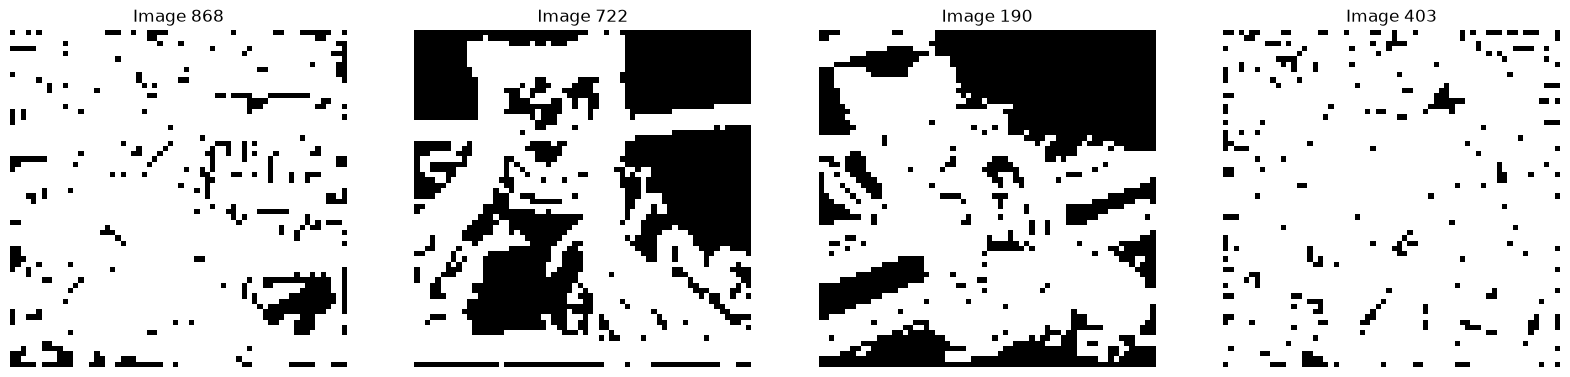

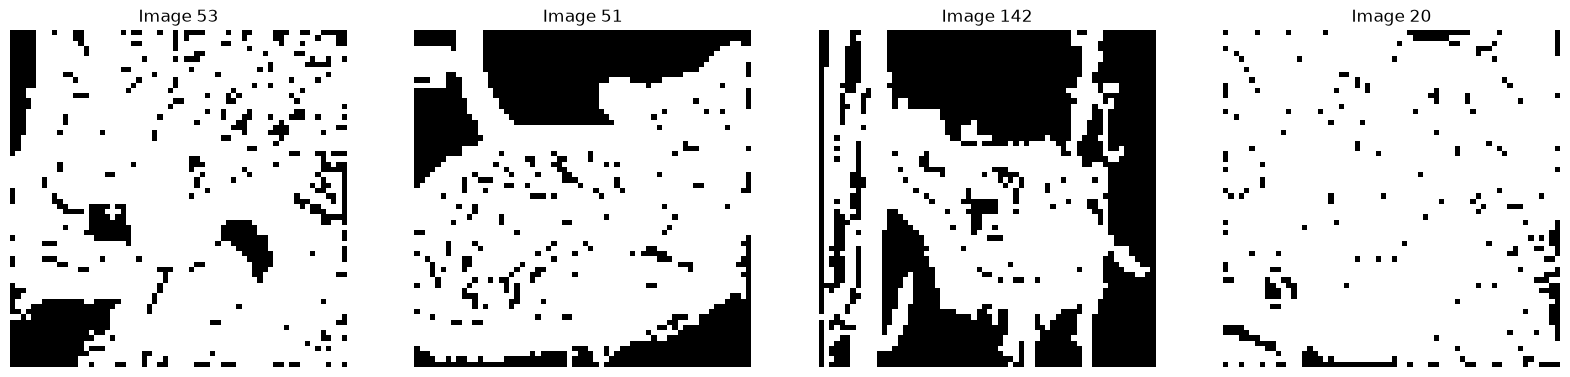

In [8]:
# Test set paths and utility variables
image_side = 256
db_path = 'DBs/CaniGatti_ML18'
exp_path = 'Experiments'
train_filelist = 'BinaryTrainingSet.txt' 
test_filelist = 'Unlabeled_BinaryTestSet.txt'
result_path = 'Es4Predictions.txt'
memory = Memory(exp_path, verbose=0) 

# Training: load the training set
train_raw_x, train_y = ml_utilities.load_labeled_dataset(train_filelist, db_path, cache=memory)
ml_utilities.shuffle_in_unison([train_raw_x, train_y], seed=1234)

# Loading labelled set, only for checking results
test_raw_x, test_raw_y = ml_utilities.load_labeled_dataset('Labeled_BinaryTestSet.txt', db_path, cache=memory)

train_features, names = build_features(train_raw_x, show_samples=True)
test_features, _ = build_features(test_raw_x, show_samples=True)

In [ ]:
DEFAULT_PARAM_GRID = {
    'C': [0.1, 1, 10 ,100, 1000],
    'gamma': ['scale', 'auto'] + list(np.logspace(-4, 0, 5)),
    'kernel': ['rbf']
}

def train_and_evaluate(train_x, train_y, test_x, test_y, name='model',
                       param_grid=None, n_folds=5, verbose=True):
    """Grid search an SVC on one feature set and evaluate it on the test set."""
    param_grid = param_grid or DEFAULT_PARAM_GRID

    grid_search_cv = GridSearchCV(SVC(), param_grid, cv=n_folds, n_jobs=-1)
    grid_search_cv.fit(train_x, train_y)

    clf = grid_search_cv.best_estimator_
    predictions = clf.predict(test_x)
    test_acc = np.mean(predictions == np.asarray(test_y))

    if verbose:
        print(f'\n{"=" * 60}\nPreprocessing: {name}\n{"=" * 60}')
        print('Combinazioni di parametri:\n', grid_search_cv.cv_results_['params'])
        print('Accuratezza media per combinazione:\n', grid_search_cv.cv_results_['mean_test_score'])
        print('Combinazione migliore:\n', grid_search_cv.best_params_)
        print('Accuratezza media della combinazione migliore: %.3f' % grid_search_cv.best_score_)
        print('Accuratezza modello testing: %.3f' % test_acc)

    return {
        'name': name,
        'best_estimator': clf,
        'best_params': grid_search_cv.best_params_,
        'cv_score': grid_search_cv.best_score_,
        'test_accuracy': test_acc,
        'grid_search': grid_search_cv,
    }

In [6]:


idx = names.index('comcon')
res = train_and_evaluate(train_features[idx], train_y,
                         test_features[idx], test_raw_y, name='comcon')

'''
results = {}
for name, tr_x, te_x in zip(names, train_features, test_features):
    results[name] = train_and_evaluate(tr_x, train_y, te_x, test_raw_y, name=name)

# Summary
print(f'\n{"Preprocessing":<15}{"CV acc":<10}{"Test acc":<10}Best params')
for name, r in results.items():
    print(f'{name:<15}{r["cv_score"]:<10.3f}{r["test_accuracy"]:<10.3f}{r["best_params"]}')

best_name = max(results, key=lambda n: results[n]['cv_score'])
print(f'\nMiglior preprocessing (per CV): {best_name}')
'''


Preprocessing: comcon
Combinazioni di parametri:
 [{'C': np.float64(2.0), 'gamma': 'scale', 'kernel': 'rbf'}, {'C': np.float64(2.0), 'gamma': 'auto', 'kernel': 'rbf'}, {'C': np.float64(2.0), 'gamma': np.float64(0.0001), 'kernel': 'rbf'}, {'C': np.float64(2.0), 'gamma': np.float64(0.001), 'kernel': 'rbf'}, {'C': np.float64(2.0), 'gamma': np.float64(0.01), 'kernel': 'rbf'}, {'C': np.float64(2.0), 'gamma': np.float64(0.1), 'kernel': 'rbf'}, {'C': np.float64(2.0), 'gamma': np.float64(1.0), 'kernel': 'rbf'}, {'C': np.float64(2.25), 'gamma': 'scale', 'kernel': 'rbf'}, {'C': np.float64(2.25), 'gamma': 'auto', 'kernel': 'rbf'}, {'C': np.float64(2.25), 'gamma': np.float64(0.0001), 'kernel': 'rbf'}, {'C': np.float64(2.25), 'gamma': np.float64(0.001), 'kernel': 'rbf'}, {'C': np.float64(2.25), 'gamma': np.float64(0.01), 'kernel': 'rbf'}, {'C': np.float64(2.25), 'gamma': np.float64(0.1), 'kernel': 'rbf'}, {'C': np.float64(2.25), 'gamma': np.float64(1.0), 'kernel': 'rbf'}, {'C': np.float64(2.5), 'g

'\nresults = {}\nfor name, tr_x, te_x in zip(names, train_features, test_features):\n    results[name] = train_and_evaluate(tr_x, train_y, te_x, test_raw_y, name=name)\n\n# Summary\nprint(f\'\n{"Preprocessing":<15}{"CV acc":<10}{"Test acc":<10}Best params\')\nfor name, r in results.items():\n    print(f\'{name:<15}{r["cv_score"]:<10.3f}{r["test_accuracy"]:<10.3f}{r["best_params"]}\')\n\nbest_name = max(results, key=lambda n: results[n][\'cv_score\'])\nprint(f\'\nMiglior preprocessing (per CV): {best_name}\')\n'

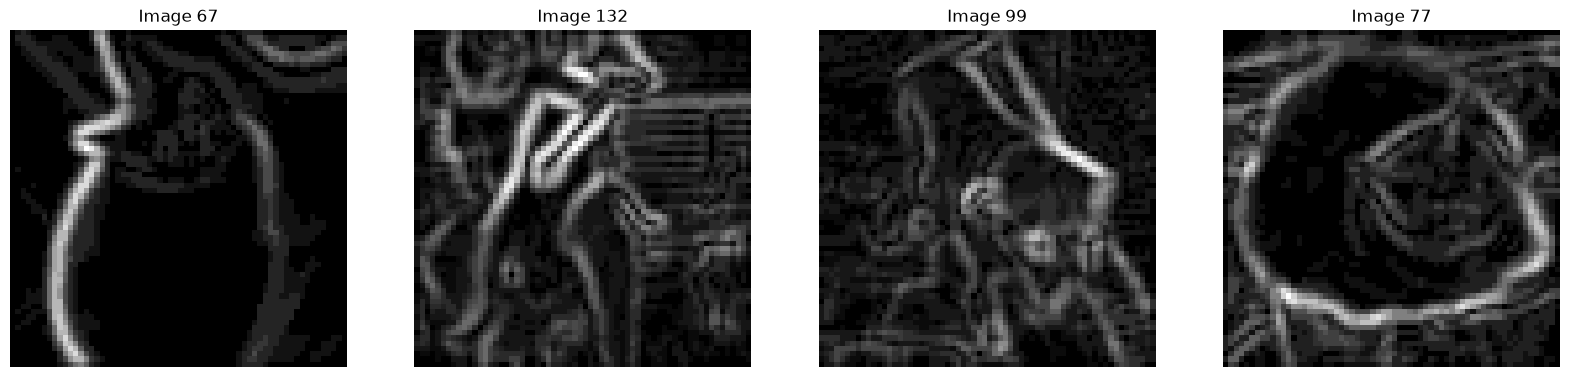

Ok


In [15]:
# Test unlabeled: stesso pre-processing e stesse HOG del training
unl_raw_x = ml_utilities.load_unlabeled_dataset(test_filelist, db_path, cache=memory)
unl_feature_x, _ = build_features(unl_raw_x)

idx = names.index('sobel')

clf = res['best_estimator']

predictions = clf.predict(unl_feature_x[idx])

with open(result_path, "w") as f:
    for prediction in predictions:
        f.write(str(int(prediction)) + '\n')
print('Ok')
